# PathSnap: Road Network, Graph and Reference Route Analysis
**Owner:** Likith

**Scope:** road-network structure (`.nodes`, `.arcs`), graph quality, and reference routes (`.route`) for every supplied trip.

**Partitions:** `train` (80 trips) and `student_test` (10 trips). Only these two partitions are in the package, so no evaluator-test data is touched. Reference routes are analysed descriptively only. Nothing here tunes preprocessing or models on them.

**Raw formats (from *Dataset Exploration*):**
- `.nodes`: `lon lat` per line, no header. Node ID = 0-based row index.
- `.arcs`: `from_node to_node` per line, no header. Arc ID = 0-based row index. Arcs are directed.
- `.route`: one arc ID per line, in travel order.
- `.track`: `lon lat timestamp` per line, no header (GPS trace, used only as a length reference here).

**Geography:** coordinates are WGS84 longitude/latitude in degrees. The dataset is global, not one city: the 90 trips lie on several continents (Section 4 prints the spread). Each trip therefore has its own local geometry.

**Distances:** Euclidean distance in degrees is not physical distance, and the east-west scale depends on latitude (1 deg lon is about 0.64 x 1 deg lat at 50 N, and shrinks further toward the poles). All lengths use the haversine great-circle formula on a sphere of radius 6371008.8 m. The error against an ellipsoid is well under 1%, which is far below the GPS noise. The one place that needs a local planar approximation (the 50 m GPS coverage check) projects each trip around its own centre.

In [1]:
import os
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from scipy.spatial import cKDTree
from matplotlib.lines import Line2D

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)


def find_data_root(start):
    """Walk up from `start` until '<...>/Student folder/Student folder/{train,student_test}' is found."""
    start = Path(start).resolve()
    for cand in [start, *start.parents]:
        root = cand / "Student folder" / "Student folder"
        if (root / "train").is_dir() and (root / "student_test").is_dir():
            return root
    raise FileNotFoundError(f"No train/ and student_test/ folders found above {start}")


_file = globals().get("__file__")
OUT_DIR = Path(_file).resolve().parent if _file else Path.cwd()
DATA_ROOT = find_data_root(OUT_DIR)
PARTITIONS = ["train", "student_test"]
EARTH_R = 6371008.8

print("Data root:", DATA_ROOT)
print("Output dir:", OUT_DIR)

Data root: C:\Users\likhi\Downloads\ML Hackathon\Student folder\Student folder
Output dir: C:\Users\likhi\Downloads\ML Hackathon\Likith


## 1. Helpers: parsing, validation and distance

In [2]:
def haversine_m(lon1, lat1, lon2, lat2):
    lon1, lat1, lon2, lat2 = (np.radians(np.asarray(x, dtype=float)) for x in (lon1, lat1, lon2, lat2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * EARTH_R * np.arcsin(np.sqrt(np.clip(a, 0, 1)))


def read_numeric_table(path, ncols):
    """Read a whitespace-separated, header-less file. Non-numeric tokens become NaN and are counted."""
    raw = pd.read_csv(path, sep=r"\s+", header=None, dtype=str, keep_default_na=False)
    if raw.shape[1] != ncols:
        raise ValueError(f"{path}: expected {ncols} columns, found {raw.shape[1]}")
    num = raw.apply(pd.to_numeric, errors="coerce")
    n_bad_rows = int(num.isna().any(axis=1).sum())
    return num, n_bad_rows


def valid_int_ids(x, hi):
    """Mask of values that are finite, integer-valued and in [0, hi). Returns (mask, int ids with -1 for invalid)."""
    x = np.asarray(x, dtype=float)
    finite = np.isfinite(x)
    xf = np.where(finite, x, -1.0)
    is_int = finite & (xf == np.floor(xf))
    ok = is_int & (xf >= 0) & (xf < hi)
    return ok, np.where(ok, xf, -1).astype(np.int64)

## 2. Per-trip processing: build the graph, check quality, analyse the reference route

Each trip gets its own road network. A spot check on three trips found no shared node coordinates, so every trip is processed separately and nothing is merged across trips.

**Node and arc indexing:** arc IDs are row indices in `.arcs`, so invalid rows are kept in place with `-1` endpoints. This keeps every later arc ID aligned with the file.

**Graph:** `nx.DiGraph`, one node per row of `.nodes` (with `lon`/`lat`). Each unique directed `(from, to)` pair becomes one edge, carrying its first `arc_id` and `length_m`. Duplicate arc rows and self-loops are kept as counted anomalies. The graph is built from all valid arcs, so no data is dropped before the checks run.

In [3]:
def clean_arcs(arcs_num, n_nodes):
    A = arcs_num.to_numpy(dtype=float)
    ok_u, ui = valid_int_ids(A[:, 0], n_nodes)
    ok_v, vi = valid_int_ids(A[:, 1], n_nodes)
    valid = ok_u & ok_v
    u = np.where(valid, ui, -1)
    v = np.where(valid, vi, -1)
    finite = np.isfinite(A).all(axis=1)
    Af = np.where(finite[:, None], A, 0.0)
    # integer-valued endpoints, regardless of range (negative or >= n_nodes counts as out-of-range)
    int_both = finite & np.all(Af == np.floor(Af), axis=1)
    stats = {
        "arc_rows": len(A),
        "arc_rows_bad_tokens": int((~finite).sum()),
        "arc_rows_out_of_range": int((int_both & ~valid).sum()),
        "arc_rows_invalid": int((~valid).sum()),
    }
    return u, v, valid, stats


def route_ids_valid(route_num, n_arcs, arc_valid):
    x = route_num[0].to_numpy(dtype=float)
    ok, ids = valid_int_ids(x, n_arcs)
    # An ID is only usable if it points at an arc row that itself has valid endpoints
    ok = ok & np.where(ok, arc_valid[np.clip(ids, 0, None)], False)
    return ok, np.where(ok, ids, -1), int(np.isnan(x).sum())


def process_trip(part, trip_id, keep_plot_data=False):
    d = DATA_ROOT / part / trip_id

    # --- nodes --------------------------------------------------------------
    nodes_num, node_bad_rows = read_numeric_table(d / f"{trip_id}.nodes", 2)
    N = len(nodes_num)
    lon = nodes_num[0].to_numpy(dtype=float)
    lat = nodes_num[1].to_numpy(dtype=float)
    coords_in_range = bool(np.all(np.isfinite(lon) & np.isfinite(lat) & (np.abs(lon) <= 180) & (np.abs(lat) <= 90)))
    n_duplicate_coords = int(pd.DataFrame({"lon": lon, "lat": lat}).duplicated().sum())

    # --- arcs ---------------------------------------------------------------
    arcs_num, _ = read_numeric_table(d / f"{trip_id}.arcs", 2)
    u, v, arc_valid, arc_stats = clean_arcs(arcs_num, N)
    M = len(u)  # arc IDs are 0..M-1
    arc_len = np.full(M, np.nan)
    arc_len[arc_valid] = haversine_m(lon[u[arc_valid]], lat[u[arc_valid]], lon[v[arc_valid]], lat[v[arc_valid]])

    # --- graph construction -------------------------------------------------
    arc_ids_valid = np.flatnonzero(arc_valid)
    pairs = pd.DataFrame({"u": u[arc_valid], "v": v[arc_valid], "arc_id": arc_ids_valid})
    uniq = pairs.drop_duplicates(["u", "v"], keep="first").reset_index(drop=True)
    uu = uniq["u"].to_numpy()
    vv = uniq["v"].to_numpy()
    aid = uniq["arc_id"].to_numpy()

    G = nx.DiGraph()
    G.add_nodes_from((i, {"lon": lon[i], "lat": lat[i]}) for i in range(N))
    G.add_edges_from(
        (a, b, {"arc_id": int(k), "length_m": float(arc_len[k])}) for a, b, k in zip(uu, vv, aid)
    )

    # --- degrees ------------------------------------------------------------
    out_deg = np.bincount(uu, minlength=N)
    in_deg = np.bincount(vv, minlength=N)
    total_deg = in_deg + out_deg
    isolated = total_deg == 0
    sink = (out_deg == 0) & (in_deg > 0)     # can be entered, cannot be left: dead end
    source = (in_deg == 0) & (out_deg > 0)   # can be left, cannot be entered
    nonloop = uu != vv
    und_pairs = np.unique(np.concatenate([uu[nonloop], vv[nonloop]]) * N
                          + np.concatenate([vv[nonloop], uu[nonloop]]))
    und_neighbours = np.bincount(und_pairs // N, minlength=N)
    degree1 = und_neighbours == 1            # exactly one undirected neighbour
    keys = uu[nonloop] * N + vv[nonloop]
    recip = np.isin(vv[nonloop] * N + uu[nonloop], keys)
    pct_reciprocal = 100 * recip.mean() if nonloop.any() else np.nan

    # --- connectivity -------------------------------------------------------
    wcc = sorted((len(c) for c in nx.weakly_connected_components(G)), reverse=True)
    scc = sorted((len(c) for c in nx.strongly_connected_components(G)), reverse=True)

    # --- arc lengths and extent --------------------------------------------
    edge_len = arc_len[aid]
    lon_min, lon_max = np.nanmin(lon), np.nanmax(lon)
    lat_min, lat_max = np.nanmin(lat), np.nanmax(lat)
    lat_mid, lon_mid = (lat_min + lat_max) / 2, (lon_min + lon_max) / 2
    width_km = haversine_m(lon_min, lat_mid, lon_max, lat_mid) / 1000
    height_km = haversine_m(lon_mid, lat_min, lon_mid, lat_max) / 1000

    graph_row = {
        "trip_id": trip_id,
        "partition": part,
        "n_nodes": N,
        "node_rows_bad_tokens": node_bad_rows,
        "coords_in_valid_range": coords_in_range,
        "duplicate_node_coords": n_duplicate_coords,
        "n_arc_rows": arc_stats["arc_rows"],
        "arc_rows_invalid": arc_stats["arc_rows_invalid"],
        "arc_rows_out_of_range": arc_stats["arc_rows_out_of_range"],
        "arc_rows_bad_tokens": arc_stats["arc_rows_bad_tokens"],
        "n_valid_arcs": int(arc_valid.sum()),
        "n_unique_directed_edges": len(uniq),
        "n_self_loops": int((uu == vv).sum()),
        "n_duplicate_arcs": int(arc_valid.sum() - len(uniq)),
        "pct_reciprocal_arcs": round(pct_reciprocal, 2),
        "n_isolated_nodes": int(isolated.sum()),
        "n_dead_end_nodes": int(sink.sum()),
        "n_source_only_nodes": int(source.sum()),
        "n_degree1_nodes": int(degree1.sum()),
        "mean_out_degree": round(out_deg.mean(), 3),
        "max_out_degree": int(out_deg.max()),
        "max_in_degree": int(in_deg.max()),
        "n_weak_components": len(wcc),
        "largest_wcc_nodes": wcc[0],
        "largest_wcc_frac": round(wcc[0] / N, 4),
        "n_strong_components": len(scc),
        "largest_scc_nodes": scc[0],
        "largest_scc_frac": round(scc[0] / N, 4),
        "lon_min": lon_min, "lon_max": lon_max, "lat_min": lat_min, "lat_max": lat_max,
        "extent_width_km": round(width_km, 2),
        "extent_height_km": round(height_km, 2),
        "total_network_km": round(np.nansum(edge_len) / 1000, 2),
        "arc_len_median_m": round(float(np.nanmedian(edge_len)), 2),
        "arc_len_max_m": round(float(np.nanmax(edge_len)), 2),
        "n_zero_length_edges": int((edge_len < 1e-6).sum()),
    }

    # --- reference route ----------------------------------------------------
    route_num, route_bad_tokens = read_numeric_table(d / f"{trip_id}.route", 1)
    r_ok, r_ids, _ = route_ids_valid(route_num, M, arc_valid)
    n_route = len(r_ids)
    ids = np.where(r_ok, r_ids, -1)
    a, b = ids[:-1], ids[1:]
    pair_ok = (a >= 0) & (b >= 0)
    ac = np.where(pair_ok, a, 0)
    bc = np.where(pair_ok, b, 0)
    connected = pair_ok & (v[ac] == u[bc])
    disconnected = pair_ok & ~connected
    uturn = connected & (v[bc] == u[ac])   # next arc is the reverse of the previous one
    gap_m = haversine_m(lon[v[ac]], lat[v[ac]], lon[u[bc]], lat[u[bc]])
    gaps = gap_m[disconnected]
    route_len_m = float(np.nansum(arc_len[r_ids[r_ok]]))

    # --- GPS track (length reference only) ----------------------------------
    trk_num, trk_bad_rows = read_numeric_table(d / f"{trip_id}.track", 3)
    tlon = trk_num[0].to_numpy(dtype=float)
    tlat = trk_num[1].to_numpy(dtype=float)
    tts = trk_num[2].to_numpy(dtype=float)
    seg = haversine_m(tlon[:-1], tlat[:-1], tlon[1:], tlat[1:])
    track_len_m = float(np.nansum(seg))
    track_in_bbox = float(np.mean((tlon >= lon_min) & (tlon <= lon_max) & (tlat >= lat_min) & (tlat <= lat_max)))

    # Coverage: share of GPS points within 50 m of any reference-route node. Uses a local
    # equirectangular projection around the trip centre, which is accurate to well under 1% at this scale.
    route_nodes = np.unique(np.concatenate([u[r_ids[r_ok]], v[r_ids[r_ok]]]))
    lat0 = np.radians(lat_mid)

    def to_xy(lo, la):
        return np.c_[np.asarray(lo) * np.cos(lat0) * 111320.0, np.asarray(la) * 110574.0]

    good = np.isfinite(tlon) & np.isfinite(tlat)
    if route_nodes.size and good.any():
        dist, _ = cKDTree(to_xy(lon[route_nodes], lat[route_nodes])).query(to_xy(tlon[good], tlat[good]))
        pct_track_near_route = 100 * float(np.mean(dist <= 50.0))
    else:
        pct_track_near_route = np.nan

    n_trans = int(pair_ok.sum())
    n_conn = int(connected.sum())
    route_row = {
        "trip_id": trip_id,
        "partition": part,
        "n_route_arcs": n_route,
        "n_unique_route_arcs": int(len(np.unique(r_ids[r_ok]))),
        "n_repeated_route_arcs": int(n_route - len(np.unique(r_ids[r_ok]))),
        "n_invalid_route_ids": int((~r_ok).sum()),
        "route_bad_tokens": route_bad_tokens,
        "n_transitions_checked": n_trans,
        "n_connected_transitions": n_conn,
        "n_disconnected_transitions": int(disconnected.sum()),
        "pct_connected_transitions": round(100 * n_conn / n_trans, 2) if n_trans else np.nan,
        "n_uturn_transitions": int(uturn.sum()),
        "median_gap_m": round(float(np.median(gaps)), 2) if gaps.size else 0.0,
        "max_gap_m": round(float(np.max(gaps)), 2) if gaps.size else 0.0,
        "route_length_m": round(route_len_m, 1),
        "route_length_km": round(route_len_m / 1000, 3),
        "mean_route_arc_len_m": round(route_len_m / max(int(r_ok.sum()), 1), 2),
        "track_points": len(tlon),
        "track_bad_rows": trk_bad_rows,
        "track_length_km": round(track_len_m / 1000, 3),
        "track_duration_s": round(float(np.nanmax(tts) - np.nanmin(tts)), 1),
        "route_to_track_length_ratio": round(route_len_m / track_len_m, 3) if track_len_m else np.nan,
        "pct_track_points_in_network_bbox": round(100 * track_in_bbox, 2),
        "pct_track_points_within_50m_of_route": round(pct_track_near_route, 2),
    }

    plot_data = None
    if keep_plot_data:
        plot_data = {
            "trip_id": trip_id, "part": part, "N": N, "M": M,
            "lon": lon, "lat": lat, "eu": uu, "ev": vv,
            "route_arcs": r_ids[r_ok], "route_u": u, "route_v": v,
            "tlon": tlon, "tlat": tlat,
            "total_deg": total_deg, "wcc": wcc, "scc": scc,
        }
    return graph_row, route_row, total_deg, plot_data

## 3. Run all 90 trips

Choose the example trip for plots first: the median-size `train` trip by node count. That keeps the figure representative instead of cherry-picked.

In [4]:
trip_index = [(p, t) for p in PARTITIONS for t in sorted(os.listdir(DATA_ROOT / p))]
node_counts = {}
for p, t in trip_index:
    with open(DATA_ROOT / p / t / f"{t}.nodes", "rb") as fh:
        node_counts[(p, t)] = sum(1 for _ in fh)
train_sorted = sorted([k for k in node_counts if k[0] == "train"], key=lambda k: node_counts[k])
EXAMPLE_PART, EXAMPLE = train_sorted[len(train_sorted) // 2]
print(f"{len(trip_index)} trips in total; example trip for plots = {EXAMPLE} ({EXAMPLE_PART}, "
      f"{node_counts[(EXAMPLE_PART, EXAMPLE)]:,} nodes)")

90 trips in total; example trip for plots = 00000066 (train, 9,609 nodes)


In [5]:
graph_rows, route_rows = [], []
pooled_deg = np.zeros(1, dtype=np.int64)
example_data = None
for part, trip_id in trip_index:
    keep = trip_id == EXAMPLE
    g_row, r_row, total_deg, pdata = process_trip(part, trip_id, keep_plot_data=keep)
    graph_rows.append(g_row)
    route_rows.append(r_row)
    cnt = np.bincount(total_deg)
    if len(cnt) > len(pooled_deg):
        pooled_deg = np.pad(pooled_deg, (0, len(cnt) - len(pooled_deg)))
    pooled_deg[: len(cnt)] += cnt
    if pdata is not None:
        example_data = pdata

graph_report = pd.DataFrame(graph_rows)
route_analysis = pd.DataFrame(route_rows)
graph_report.to_csv(OUT_DIR / "graph_report.csv", index=False)
route_analysis.to_csv(OUT_DIR / "route_analysis.csv", index=False)
print("Wrote graph_report.csv", graph_report.shape, "and route_analysis.csv", route_analysis.shape)

Wrote graph_report.csv (90, 38) and route_analysis.csv (90, 24)


## 4. Graph quality summary

In [6]:
quality_cols = [
    "n_nodes", "n_valid_arcs", "n_unique_directed_edges", "arc_rows_invalid", "n_self_loops",
    "n_duplicate_arcs", "pct_reciprocal_arcs", "n_isolated_nodes", "n_dead_end_nodes",
    "n_source_only_nodes", "n_degree1_nodes", "duplicate_node_coords", "n_zero_length_edges",
    "n_weak_components", "largest_wcc_frac", "n_strong_components", "largest_scc_frac",
    "extent_width_km", "extent_height_km", "total_network_km", "arc_len_median_m",
]
summary = graph_report.groupby("partition")[quality_cols].agg(["min", "median", "max"]).T
print(summary.to_string())
print()
print("Invalid-data totals (all trips):")
print(graph_report[["node_rows_bad_tokens", "arc_rows_bad_tokens", "arc_rows_out_of_range",
                    "arc_rows_invalid", "n_self_loops", "n_isolated_nodes", "n_dead_end_nodes",
                    "n_source_only_nodes"]].sum().to_string())
print("\nCoordinates in valid range for all trips:", bool(graph_report.coords_in_valid_range.all()))
centre_lon = (graph_report.lon_min + graph_report.lon_max) / 2
centre_lat = (graph_report.lat_min + graph_report.lat_max) / 2
print(f"Trip centres span lon {centre_lon.min():.2f} to {centre_lon.max():.2f}, "
      f"lat {centre_lat.min():.2f} to {centre_lat.max():.2f} (global spread; lon-first order consistent)")
print("Trips with centre in the northern hemisphere:", int((centre_lat > 0).sum()),
      "| southern:", int((centre_lat < 0).sum()))
print("Trips with >1 weak component:", int((graph_report.n_weak_components > 1).sum()), "of", len(graph_report))

partition                       student_test         train
n_nodes                 min       1770.00000     299.00000
                        median    6596.50000    9608.00000
                        max      26635.00000  155003.00000
n_valid_arcs            min       3577.00000     649.00000
                        median   13145.00000   19526.50000
                        max      56027.00000  307392.00000
n_unique_directed_edges min       3575.00000     649.00000
                        median   13112.00000   19524.50000
                        max      55998.00000  307263.00000
arc_rows_invalid        min          0.00000       0.00000
                        median       0.00000       0.00000
                        max          0.00000       0.00000
n_self_loops            min          0.00000       0.00000
                        median       0.00000       0.00000
                        max          1.00000       4.00000
n_duplicate_arcs        min          0.00000       0.000

## 5. Reference route summary

In [7]:
rt_cols = ["n_route_arcs", "n_invalid_route_ids", "n_uturn_transitions", "n_disconnected_transitions",
           "pct_connected_transitions", "max_gap_m", "route_length_km", "track_length_km",
           "route_to_track_length_ratio", "pct_track_points_within_50m_of_route"]
print(route_analysis.groupby("partition")[rt_cols].agg(["min", "median", "max"]).T.to_string())
print()
print("Trips with any disconnected transition:", int((route_analysis.n_disconnected_transitions > 0).sum()),
      "of", len(route_analysis))
print("Total route arc IDs checked:", int(route_analysis.n_route_arcs.sum()),
      "| invalid:", int(route_analysis.n_invalid_route_ids.sum()))

partition                                    student_test      train
n_route_arcs                         min          95.0000    59.0000
                                     median      250.0000   280.0000
                                     max        1323.0000  2266.0000
n_invalid_route_ids                  min           0.0000     0.0000
                                     median        0.0000     0.0000
                                     max           0.0000     0.0000
n_uturn_transitions                  min           0.0000     0.0000
                                     median        0.0000     0.0000
                                     max           3.0000     9.0000
n_disconnected_transitions           min           0.0000     0.0000
                                     median        0.0000     0.0000
                                     max           1.0000     3.0000
pct_connected_transitions            min          99.7300    98.1300
                                  

## 6. Visualisations

Colours follow the dataviz palette: blue `#2a78d6` and orange `#eb6834` are the first two categorical slots. Both pass the colour-vision-deficiency and contrast checks on the light surface. Grey marks the road network, and the route and GPS track carry their own colours with legends.

In [8]:
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK2, NET, SURFACE = "#0b0b0b", "#52514e", "#9c9b96", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": NET, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e4e3df", "grid.linewidth": 0.6, "legend.frameon": False,
})

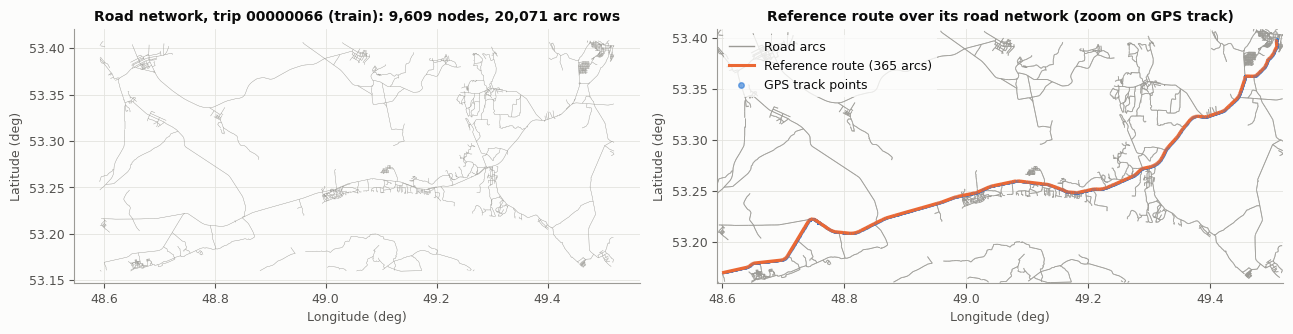

In [9]:
# Figure 1: road network of the example trip (left) and the reference route over its track (right)
ex = example_data
ex_N = ex["N"]
seg_all = np.stack([np.c_[ex["lon"][ex["eu"]], ex["lat"][ex["eu"]]],
                    np.c_[ex["lon"][ex["ev"]], ex["lat"][ex["ev"]]]], axis=1)
ra = ex["route_arcs"]
seg_route = np.stack([np.c_[ex["lon"][ex["route_u"][ra]], ex["lat"][ex["route_u"][ra]]],
                      np.c_[ex["lon"][ex["route_v"][ra]], ex["lat"][ex["route_v"][ra]]]], axis=1)
mid_lat = np.nanmean(ex["lat"])

fig, (axL, axR) = plt.subplots(1, 2, figsize=(13, 6.4))
axL.add_collection(LineCollection(seg_all, colors=NET, linewidths=0.25, alpha=0.7))
axL.autoscale_view()
axL.set_aspect(1 / np.cos(np.radians(mid_lat)))
axL.set_title(f"Road network, trip {ex['trip_id']} ({ex['part']}): "
              f"{ex_N:,} nodes, {ex['M']:,} arc rows")
axL.set_xlabel("Longitude (deg)")
axL.set_ylabel("Latitude (deg)")

pad = 0.01
x0, x1 = ex["tlon"].min() - pad, ex["tlon"].max() + pad
y0, y1 = ex["tlat"].min() - pad, ex["tlat"].max() + pad
inside = ((ex["lon"][ex["eu"]] >= x0) & (ex["lon"][ex["eu"]] <= x1) & (ex["lat"][ex["eu"]] >= y0) & (ex["lat"][ex["eu"]] <= y1)) | \
         ((ex["lon"][ex["ev"]] >= x0) & (ex["lon"][ex["ev"]] <= x1) & (ex["lat"][ex["ev"]] >= y0) & (ex["lat"][ex["ev"]] <= y1))
axR.add_collection(LineCollection(seg_all[inside], colors=NET, linewidths=0.6, alpha=0.8))
axR.scatter(ex["tlon"], ex["tlat"], s=3, color=BLUE, alpha=0.45, linewidths=0, zorder=2)
axR.add_collection(LineCollection(seg_route, colors=ORANGE, linewidths=2.4, zorder=3))
axR.set_xlim(x0, x1)
axR.set_ylim(y0, y1)
axR.set_aspect(1 / np.cos(np.radians(mid_lat)))
axR.set_title("Reference route over its road network (zoom on GPS track)")
axR.set_xlabel("Longitude (deg)")
axR.set_ylabel("Latitude (deg)")
axR.legend(handles=[
    Line2D([0], [0], color=NET, lw=1, label="Road arcs"),
    Line2D([0], [0], color=ORANGE, lw=2.2, label=f"Reference route ({len(ra)} arcs)"),
    Line2D([0], [0], marker="o", ls="", color=BLUE, ms=4, alpha=0.6, label="GPS track points"),
], loc="upper left", frameon=True, facecolor=SURFACE, edgecolor="none")
fig.tight_layout()
fig.savefig(OUT_DIR / "graph_visualization.png", dpi=150)

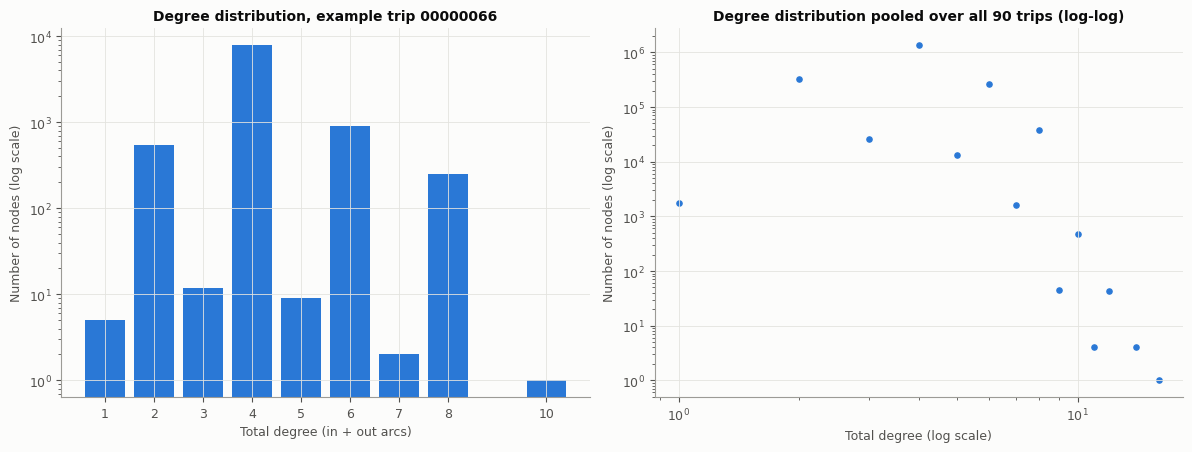

In [10]:
# Figure 2: degree distributions (example trip, and pooled across all 90 trips)
fig, (axL, axR) = plt.subplots(1, 2, figsize=(12, 4.6))
ex_cnt = np.bincount(ex["total_deg"])
ks = np.arange(len(ex_cnt))
keep_k = (ks >= 1) & (ex_cnt > 0)
axL.bar(ks[keep_k], ex_cnt[keep_k], color=BLUE, width=0.8)
axL.set_yscale("log")
axL.set_xlabel("Total degree (in + out arcs)")
axL.set_ylabel("Number of nodes (log scale)")
axL.set_title(f"Degree distribution, example trip {ex['trip_id']}")
axL.set_xticks(ks[keep_k][:16])

pk = np.arange(len(pooled_deg))
keep_p = (pk >= 1) & (pooled_deg > 0)
axR.scatter(pk[keep_p], pooled_deg[keep_p], s=14, color=BLUE)
axR.set_xscale("log")
axR.set_yscale("log")
axR.set_xlabel("Total degree (log scale)")
axR.set_ylabel("Number of nodes (log scale)")
axR.set_title("Degree distribution pooled over all 90 trips (log-log)")
fig.tight_layout()
fig.savefig(OUT_DIR / "degree_distribution.png", dpi=150)

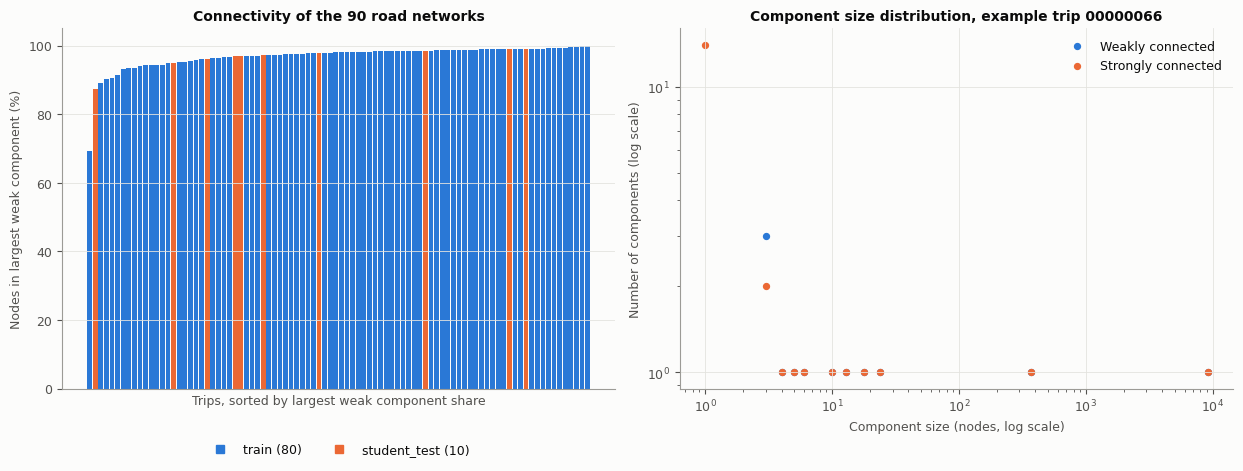

In [11]:
# Figure 3: connected components (per-trip largest-WCC share; component size distribution for the example trip)
fig, (axL, axR) = plt.subplots(1, 2, figsize=(12.5, 4.8))
gr = graph_report.sort_values("largest_wcc_frac").reset_index(drop=True)
colours = [BLUE if p == "train" else ORANGE for p in gr.partition]
axL.bar(gr.index, gr.largest_wcc_frac * 100, color=colours, width=0.85)
axL.set_xlabel("Trips, sorted by largest weak component share")
axL.set_ylabel("Nodes in largest weak component (%)")
axL.set_title("Connectivity of the 90 road networks")
axL.set_xticks([])
axL.legend(handles=[Line2D([0], [0], marker="s", ls="", color=BLUE, label="train (80)"),
                    Line2D([0], [0], marker="s", ls="", color=ORANGE, label="student_test (10)")],
           loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)

for sizes, label, col in [(ex["wcc"], "Weakly connected", BLUE), (ex["scc"], "Strongly connected", ORANGE)]:
    vc = pd.Series(sizes).value_counts().sort_index()
    axR.scatter(vc.index, vc.values, s=18, color=col, label=label)
axR.set_xscale("log")
axR.set_yscale("log")
axR.set_xlabel("Component size (nodes, log scale)")
axR.set_ylabel("Number of components (log scale)")
axR.set_title(f"Component size distribution, example trip {ex['trip_id']}")
axR.legend(loc="upper right")
fig.tight_layout()
fig.savefig(OUT_DIR / "component_analysis.png", dpi=150)

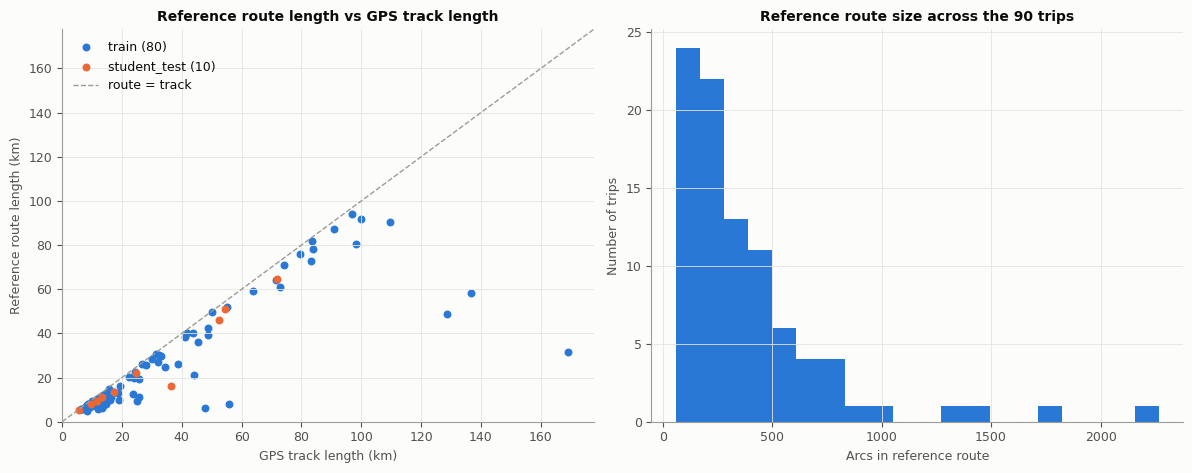

In [12]:
# Figure 4: reference route length vs GPS track length, and route arc counts
fig, (axL, axR) = plt.subplots(1, 2, figsize=(12, 4.8))
for part, col in [("train", BLUE), ("student_test", ORANGE)]:
    s = route_analysis[route_analysis.partition == part]
    axL.scatter(s.track_length_km, s.route_length_km, s=22, color=col, label=f"{part} ({len(s)})")
lim = [0, max(route_analysis.track_length_km.max(), route_analysis.route_length_km.max()) * 1.05]
axL.plot(lim, lim, color=NET, lw=1, ls="--", label="route = track")
axL.set_xlim(lim)
axL.set_ylim(lim)
axL.set_xlabel("GPS track length (km)")
axL.set_ylabel("Reference route length (km)")
axL.set_title("Reference route length vs GPS track length")
axL.legend(loc="upper left")

axR.hist(route_analysis.n_route_arcs, bins=20, color=BLUE)
axR.set_xlabel("Arcs in reference route")
axR.set_ylabel("Number of trips")
axR.set_title("Reference route size across the 90 trips")
fig.tight_layout()
fig.savefig(OUT_DIR / "route_analysis.png", dpi=150)

## 7. Save outputs

Outputs written to this folder:
- `graph_report.csv`: one row per trip, graph quality and connectivity.
- `route_analysis.csv`: one row per trip, reference route checks and lengths.
- `graph_visualization.png`, `degree_distribution.png`, `component_analysis.png`, `route_analysis.png`.

Findings and interpretation are in `graph_findings.md`.

In [13]:
print("Done. Files in", OUT_DIR)
for f in sorted(OUT_DIR.iterdir()):
    if f.suffix in {".csv", ".png", ".md", ".py", ".ipynb"}:
        print("  ", f.name)

Done. Files in C:\Users\likhi\Downloads\ML Hackathon\Likith
   component_analysis.png
   degree_distribution.png
   graph_report.csv
   graph_visualization.png
   road_network_eda.ipynb
   road_network_eda.py
   route_analysis.csv
   route_analysis.png
